Training completed!
Final epsilon: 0.01


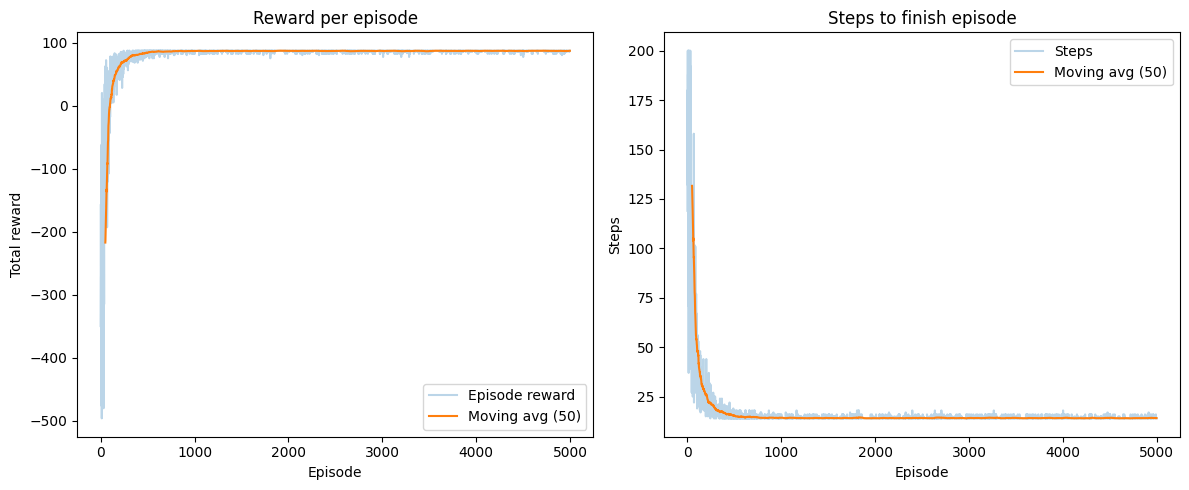

Goal reached!
Path length: 14
Path: [(0, 0), (0, 1), (1, 1), (1, 2), (2, 2), (3, 2), (3, 3), (4, 3), (5, 3), (6, 3), (7, 3), (7, 4), (7, 5), (7, 6), (7, 7)]


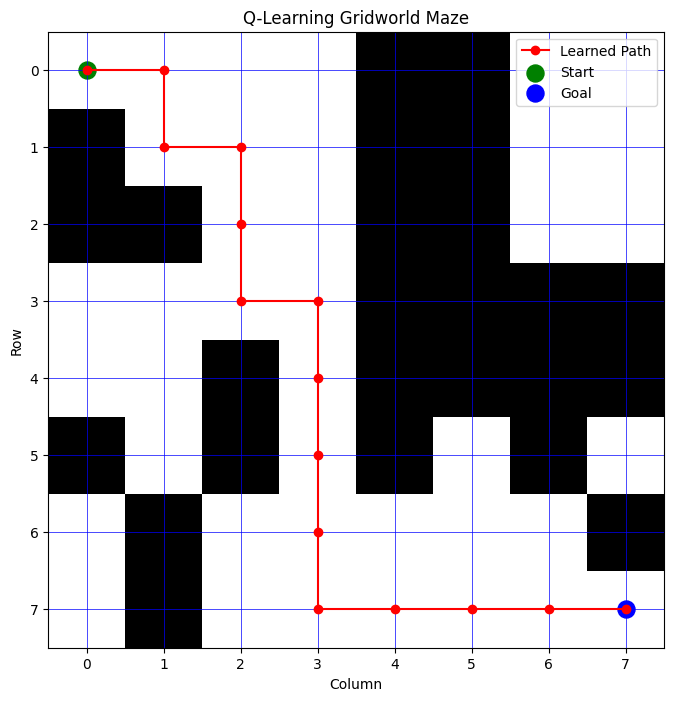

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import random

# 1. Define the maze
MAZE = [
    "S...##..",
    "#...##..",
    "##..##..",
    "....####",
    "..#.####",
    "#.#.#.#.",
    ".#.....#",
    ".#.....G"
]

rewards = []
steps_per_episode = []

# 2. Define actions and movement directions
ACTIONS = ["UP", "DOWN", "LEFT", "RIGHT"]

DELTAS = [
    (-1, 0),  # UP
    (1, 0),   # DOWN
    (0, -1),  # LEFT
    (0, 1)    # RIGHT
]

ROWS = len(MAZE)
COLUMNS = len(MAZE[0])

START = (0, 0)
GOAL = (7, 7)

NUM_ACTIONS = len(ACTIONS)

# 3. Initialize Q-table
Q = np.zeros((ROWS, COLUMNS, NUM_ACTIONS))

# 4. Define the movement function
def move(position, action):
    row, col = position

    dr, dc = DELTAS[action]

    new_row = row + dr
    new_col = col + dc

    # Check maze boundaries
    if not (0 <= new_row < ROWS and
            0 <= new_col < COLUMNS):
        return position, -5, False

    # Check for wall
    if MAZE[new_row][new_col] == "#":
        return position, -5, False

    new_position = (new_row, new_col)

    # Check whether the goal is reached
    if new_position == GOAL:
        return new_position, 100, True

    # Normal move
    return new_position, -1, False


# 5. Define Q-learning parameters
LEARNING_RATE = 0.1
DISCOUNT_FACTOR = 0.9
EPSILON = 1.0
EPSILON_DECAY = 0.995
MIN_EPSILON = 0.01
EPISODES = 5000

# 6. Train the agent
for episode in range(EPISODES):
    state = START
    done = False
    steps = 0
    max_steps = 200
    total_reward = 0

    while not done and steps < max_steps:

        row, col = state

        # Epsilon-greedy action selection
        if random.random() < EPSILON:
            action = random.randint(0, NUM_ACTIONS - 1)
        else:
            action = np.argmax(Q[row, col])

        # Perform the action
        next_state, reward, done = move(state, action)

        row, col = state
        next_row, next_col = next_state

        # Q-learning update
        old_value = Q[row, col, action]
        next_max = np.max(Q[next_row, next_col])

        Q[row, col, action] = old_value + LEARNING_RATE * (
            reward
            + DISCOUNT_FACTOR * next_max * (not done)
            - old_value
        )

        # Move to the next state
        state = next_state
        steps += 1

        total_reward += reward

    rewards.append(total_reward)
    steps_per_episode.append(steps)

    # Reduce exploration
    EPSILON = max(
        MIN_EPSILON,
        EPSILON * EPSILON_DECAY
    )

print("Training completed!")
print("Final epsilon:", EPSILON)

# 7. Plot training performance

window = 50

moving_avg_rewards = np.convolve(
    rewards, np.ones(window) / window, mode="valid"
)

moving_avg_steps = np.convolve(
    steps_per_episode, np.ones(window) / window, mode="valid"
)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Reward per episode
axes[0].plot(rewards, alpha=0.3, label="Episode reward")
axes[0].plot(
    range(window - 1, len(rewards)),
    moving_avg_rewards,
    label="Moving avg (50)"
)
axes[0].set_title("Reward per episode")
axes[0].set_xlabel("Episode")
axes[0].set_ylabel("Total reward")
axes[0].legend()

# Steps per episode
axes[1].plot(steps_per_episode, alpha=0.3, label="Steps")
axes[1].plot(
    range(window - 1, len(steps_per_episode)),
    moving_avg_steps,
    label="Moving avg (50)"
)
axes[1].set_title("Steps to finish episode")
axes[1].set_xlabel("Episode")
axes[1].set_ylabel("Steps")
axes[1].legend()

plt.tight_layout()
plt.show()


# 7. Find the learned path
state = START
path = [state]
visited = {state}

for _ in range(ROWS * COLUMNS * 4):
    if state == GOAL:
        break

    row, col = state
    action = np.argmax(Q[row, col])

    next_state, reward, done = move(state, action)

    # Stop if the agent gets stuck or loops
    if next_state == state or next_state in visited:
        print("Agent got stuck or entered a loop.")
        break

    state = next_state
    path.append(state)
    visited.add(state)

if path[-1] == GOAL:
    print("Goal reached!")
    print("Path length:", len(path) - 1)
    print("Path:", path)
else:
    print("Goal not reached. Try training for more episodes.")


# 8. Visualize the maze and learned path
grid = np.zeros((ROWS, COLUMNS))

for r in range(ROWS):
    for c in range(COLUMNS):
        if MAZE[r][c] == "#":
            grid[r, c] = 1

plt.figure(figsize=(8, 8))
plt.imshow(grid, cmap="gray_r")

# Draw grid lines
plt.xticks(range(COLUMNS))
plt.yticks(range(ROWS))
plt.grid(True, color="blue", linewidth=0.5)

# Draw the learned path
if path:
    path_rows = [p[0] for p in path]
    path_cols = [p[1] for p in path]
    plt.plot(path_cols, path_rows, "ro-", label="Learned Path")

# Mark start and goal
plt.scatter(START[1], START[0], color="green", label="Start", s = 150)
plt.scatter(GOAL[1], GOAL[0], color="blue", s=150, label="Goal")

plt.title("Q-Learning Gridworld Maze")
plt.xlabel("Column")
plt.ylabel("Row")
plt.legend()
plt.show()